# Rusham 03 — Disjoint-split Diffusion Policy analysis (Windows / RTX 4000 Ada)

**Purpose:** Compare independently trained **pool A vs pool B** models at **N=50** and **N=90** on the **same held-out human Push-T observations**. Uses your existing `final_ema_fp16.pt` checkpoints; **no training happens in this notebook**.

**Inputs:** Local `dp_memorization` project from `Rusham_02`, cached Push-T dataset, `splits.json`, four model checkpoints, pinned Diffusion Policy Git repository. **Output:** paired predictions `.npz`, per-observation `.csv`, summary `.csv`/`.json`, and figures under `dp_memorization/disjoint_split/`.

**Important scientific caveat:** Agreement measures *policy consistency*, not proof of memorization or good behavior. Define the action-distance threshold **before inspecting final agreement results**; the default `0.10` below is a **provisional example**, not a team-approved value.

Run cells top-to-bottom in the same **Diffusion Policy (CUDA)** VS Code environment you used for training. You can use a CPU, but inference will be slower.

## Step 1 — Settings and path checks

In [1]:
from pathlib import Path
import os, sys, json, time, copy, types, subprocess, shutil, random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display

# If this notebook is next to your training notebook, leave PROJECT_DIR = None.
# Otherwise set an absolute path, e.g. r"C:\Users\rrbhat\Projects\dp_memorization\dp_memorization"
PROJECT_DIR = None
WORK_DIR = Path.cwd().resolve()
PROJECT_DIR = Path(PROJECT_DIR).expanduser().resolve() if PROJECT_DIR else WORK_DIR / "dp_memorization"
RUNS_DIR = PROJECT_DIR / "runs"
OUT_DIR = PROJECT_DIR / "disjoint_split"
OUT_DIR.mkdir(parents=True, exist_ok=True)

DATA_DIR = PROJECT_DIR / "data_extracted"
SPLITS_PATH = PROJECT_DIR / "splits.json"
REPO_DIR = WORK_DIR / "diffusion_policy"
REPO_COMMIT = "5ba07ac6661db573af695b419a7947ecb704690f"
PAIRS = [50, 90]  # only sizes where *you* have both pool-A and pool-B models
TOTAL_STEPS = 100_000
MODEL_SEED = 2
OBS_DIM, ACTION_DIM = 20, 2
HORIZON, N_OBS_STEPS, N_ACTION_STEPS = 16, 2, 8
HELDOUT_STRIDE = 8
BATCH_SIZE = 32  # reduce to 8 or 16 if GPU runs out of memory
INFERENCE_SEED = 2026
# REQUIRED BEFORE FINAL SCIENTIFIC ANALYSIS: confirm with team / preregister the threshold.
# Distances below are Euclidean distances after dividing each action dimension by
# its full-dataset range (NOT distances in pixels).
AGREEMENT_THRESHOLD = 0.10   # PROVISIONAL, edit to team's agreed fixed threshold

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Working directory:", WORK_DIR)
print("Project directory:", PROJECT_DIR)
print("Inference device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")
assert SPLITS_PATH.is_file(), f"Missing {SPLITS_PATH}. Set PROJECT_DIR above to your existing training output folder."
for n in PAIRS:
    for pool in ("A", "B"):
        path = RUNS_DIR / f"N{n:03d}_pool{pool}_seed{MODEL_SEED}" / "final_ema_fp16.pt"
        assert path.is_file(), f"Missing model checkpoint: {path}"
        print("Found:", path)
assert AGREEMENT_THRESHOLD > 0
print("Checkpoint paths verified. No model training will occur.")

c:\Users\rrbhat\Projects\dp_memorization\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Working directory: C:\Users\rrbhat\Downloads
Project directory: C:\Users\rrbhat\Downloads\dp_memorization
Inference device: cuda NVIDIA RTX 4000 Ada Generation
Found: C:\Users\rrbhat\Downloads\dp_memorization\runs\N050_poolA_seed2\final_ema_fp16.pt
Found: C:\Users\rrbhat\Downloads\dp_memorization\runs\N050_poolB_seed2\final_ema_fp16.pt
Found: C:\Users\rrbhat\Downloads\dp_memorization\runs\N090_poolA_seed2\final_ema_fp16.pt
Found: C:\Users\rrbhat\Downloads\dp_memorization\runs\N090_poolB_seed2\final_ema_fp16.pt
Checkpoint paths verified. No model training will occur.


## Step 2 — Load the identical repository and dataset used in training

This reproduces the dependency compatibility setup from your **Rusham 02** notebook. It reuses the already-extracted data; there is no need to download a new copy.

In [2]:
REPO_DIR = WORK_DIR / "diffusion_policy"
REPO_COMMIT = "5ba07ac6661db573af695b419a7947ecb704690f"
if not REPO_DIR.is_dir():
    raise FileNotFoundError(f"Repository not found: {REPO_DIR}. Open this notebook in the SAME VS Code project directory as Rusham_02.")
# We DO NOT checkout automatically: avoid changing a repository in another running notebook.
if shutil.which("git"):
    actual_commit = subprocess.check_output(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], text=True).strip()
    assert actual_commit == REPO_COMMIT, f"Wrong repository commit: {actual_commit}. Expected {REPO_COMMIT}."
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

# ---- compatibility fixes for a current Colab ------------------------------
os.environ["SDL_VIDEODRIVER"] = "dummy"          # pygame without a display
os.environ["PYGAME_HIDE_SUPPORT_PROMPT"] = "1"

# The Push-T environment only uses `gym` for type declarations (Env, spaces.Box,
# and a registration call). A tiny stand-in avoids installing the old gym 0.21.
_gym = types.ModuleType("gym")
_spaces = types.ModuleType("gym.spaces")
_envs = types.ModuleType("gym.envs")
_registration = types.ModuleType("gym.envs.registration")
class _Env:
    metadata = {}
class _Wrapper(_Env):
    def __init__(self, env):
        self.env = env
class _Box:
    def __init__(self, low=None, high=None, shape=None, dtype=None):
        self.low, self.high, self.shape, self.dtype = low, high, shape, dtype
_spaces.Box, _spaces.Dict = _Box, dict
_registration.register = lambda *args, **kwargs: None
_envs.registration = _registration
_gym.Env, _gym.Wrapper, _gym.spaces, _gym.envs = _Env, _Wrapper, _spaces, _envs
sys.modules.update({"gym": _gym, "gym.spaces": _spaces,
                    "gym.envs": _envs, "gym.envs.registration": _registration})

# matplotlib >= 3.9 removed cm.get_cmap, which the keypoint code still calls.
import matplotlib, matplotlib.cm
if not hasattr(matplotlib.cm, "get_cmap"):
    matplotlib.cm.get_cmap = matplotlib.colormaps.get_cmap

# ---- imports ----------------------------------------------------------------
import numpy as np
import torch
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from diffusers.schedulers.scheduling_ddpm import DDPMScheduler
from diffusers.optimization import get_cosine_schedule_with_warmup

from diffusion_policy.dataset.pusht_dataset import PushTLowdimDataset
from diffusion_policy.common.sampler import SequenceSampler
from diffusion_policy.model.diffusion.conditional_unet1d import ConditionalUnet1D
from diffusion_policy.policy.diffusion_unet_lowdim_policy import DiffusionUnetLowdimPolicy
from diffusion_policy.model.diffusion.ema_model import EMAModel

device = DEVICE
if torch.cuda.is_available() and torch.version.cuda is not None:
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
print("Model imports ready. Device:", device)

Model imports ready. Device: cuda


In [3]:
import glob
matches = sorted(glob.glob(str(DATA_DIR / "**" / "pusht_cchi_v7_replay.zarr"), recursive=True))
assert matches, f"No extracted Push-T replay dataset found beneath {DATA_DIR}. Rerun Step 4 of Rusham_02 if needed."
ZARR_PATH = matches[0]
dataset = PushTLowdimDataset(zarr_path=ZARR_PATH, horizon=HORIZON,
                             pad_before=N_OBS_STEPS - 1,
                             pad_after=N_ACTION_STEPS - 1,
                             val_ratio=0.0, max_train_episodes=None)
replay = dataset.replay_buffer
episode_ends = np.asarray(replay.episode_ends[:], dtype=np.int64)
assert len(episode_ends) == 206, f"Expected 206 demos, got {len(episode_ends)}"
with open(SPLITS_PATH, encoding="utf-8") as f:
    splits = json.load(f)
heldout = [int(x) for x in splits["heldout"]]
assert len(heldout) == 20 and len(set(heldout)) == 20
assert not set(heldout).intersection(set(splits["pool_A"]) | set(splits["pool_B"]))
assert not set(splits["pool_A"]).intersection(splits["pool_B"])
# The original notebook's fixed split seed was 2026. Check the file exactly.
perm = np.random.default_rng(2026).permutation(206)
assert heldout == sorted(int(x) for x in perm[:20]), "Heldout differs from training notebook's fixed split"
print("Dataset:", ZARR_PATH)
print("Held-out demo IDs:", heldout)
print("Replay buffer keys:", list(replay.keys()))
assert "keypoint" in replay and "state" in replay and "action" in replay, "Unexpected replay keys; inspect the printed keys."

Dataset: C:\Users\rrbhat\Downloads\dp_memorization\data_extracted\pusht\pusht_cchi_v7_replay.zarr
Held-out demo IDs: [2, 10, 16, 22, 31, 33, 47, 60, 62, 82, 86, 98, 112, 133, 141, 142, 147, 153, 175, 204]
Replay buffer keys: ['keypoint', 'state', 'action']


## Step 3 — Construct matched held-out observation histories

For each of the 20 held-out human demonstrations, sample at timestamps **0, 8, 16, ...** (local episode time). Construct the same **two-observation history** the model uses in simulator evaluation; at time zero the first observation is repeated. Save episode ID and local timestamp for alignment. These are demonstration observations, **not** observations from separate model rollouts.

In [4]:
# PushTLowdimDataset constructs its 20-D observations from keypoint + state.
# The raw replay buffer does NOT contain an "obs" key. Use the exact training transform.
full_data = dataset._sample_to_data(replay)
raw_obs = np.asarray(full_data["obs"], dtype=np.float32)
raw_act = np.asarray(full_data["action"], dtype=np.float32)
assert raw_obs.ndim == 2 and raw_obs.shape[1] == OBS_DIM, raw_obs.shape
assert raw_act.ndim == 2 and raw_act.shape[1] == ACTION_DIM, raw_act.shape
assert len(raw_obs) == len(raw_act) == int(episode_ends[-1])

obs_list, episode_ids, local_times = [], [], []
for ep in heldout:
    start = 0 if ep == 0 else int(episode_ends[ep-1])
    end = int(episode_ends[ep])
    for t in range(0, end - start, HELDOUT_STRIDE):
        current = raw_obs[start + t]
        previous = raw_obs[start + max(0, t-1)]
        obs_list.append(np.stack([previous, current], axis=0))
        episode_ids.append(ep)
        local_times.append(t)

matched_obs = np.stack(obs_list).astype(np.float32)
episode_ids = np.asarray(episode_ids, dtype=np.int32)
local_times = np.asarray(local_times, dtype=np.int32)
assert matched_obs.shape[1:] == (2, OBS_DIM)
assert np.isfinite(matched_obs).all()

# Fixed action scaling from the full original action dataset, not per-model predictions.
action_min = raw_act.min(axis=0)
action_max = raw_act.max(axis=0)
action_scale = np.maximum(action_max - action_min, 1e-6).astype(np.float32)
print(f"Held-out matched observations: {len(matched_obs)} across {len(heldout)} demos")
print("Input shape:", matched_obs.shape, "| action scaling range:", action_scale)
np.savez_compressed(OUT_DIR / "matched_heldout_obs.npz", obs=matched_obs,
                    episode_ids=episode_ids, timestamps=local_times,
                    heldout_ids=np.asarray(heldout), action_scale=action_scale)

Held-out matched observations: 300 across 20 demos
Input shape: (300, 2, 20) | action scaling range: [499. 486.]


## Step 4 — Reconstruct the same inference policy and load existing EMA checkpoints

Use **identical** architecture, scheduler, observation history, prediction horizon, and normalizer structure as your training notebook. The normalizer values are **loaded from the checkpoint** (not independently fitted here). Only **one policy at a time** is held on the GPU to conserve VRAM.

In [5]:
# Construct the normalizer *structure* before restoring all checkpoint parameters.
# The checkpoint includes normalizer state; loading it replaces these values.
normalizer = dataset.get_normalizer()

def build_policy():
    model = ConditionalUnet1D(input_dim=ACTION_DIM, local_cond_dim=None,
                              global_cond_dim=OBS_DIM * N_OBS_STEPS,
                              diffusion_step_embed_dim=256,
                              down_dims=[256, 512, 1024], kernel_size=5, n_groups=8,
                              cond_predict_scale=True)
    scheduler = DDPMScheduler(num_train_timesteps=100, beta_start=0.0001,
                              beta_end=0.02, beta_schedule="squaredcos_cap_v2",
                              variance_type="fixed_small", clip_sample=True,
                              prediction_type="epsilon")
    p = DiffusionUnetLowdimPolicy(model=model, noise_scheduler=scheduler,
                                  horizon=HORIZON, obs_dim=OBS_DIM,
                                  action_dim=ACTION_DIM, n_action_steps=N_ACTION_STEPS,
                                  n_obs_steps=N_OBS_STEPS, num_inference_steps=100,
                                  obs_as_local_cond=False, obs_as_global_cond=True,
                                  pred_action_steps_only=False, oa_step_convention=True)
    p.set_normalizer(copy.deepcopy(normalizer))
    return p

def run_name(n, pool):
    return f"N{n:03d}_pool{pool}_seed{MODEL_SEED}"

def load_policy(n, pool):
    name = run_name(n, pool)
    cfg_path = RUNS_DIR / name / "config.json"
    assert cfg_path.is_file(), f"Missing config file: {cfg_path}"
    with open(cfg_path, encoding="utf-8") as f:
        cfg = json.load(f)
    for k,v in (("n_demos", n), ("pool", pool), ("seed", MODEL_SEED),
                ("total_steps", TOTAL_STEPS), ("quick_test", False),
                ("repo_commit", REPO_COMMIT)):
        assert cfg.get(k) == v, f"{name}: config {k}={cfg.get(k)!r}, expected {v!r}"
    expected = sorted(splits[f"pool_{pool}"][:n])
    assert sorted(cfg["train_episodes"]) == expected, f"{name}: training split does not match splits.json"
    assert not set(cfg["train_episodes"]).intersection(heldout)
    p = build_policy()
    checkpoint = torch.load(RUNS_DIR / name / "final_ema_fp16.pt", map_location="cpu", weights_only=True)
    p.load_state_dict(checkpoint, strict=True)
    del checkpoint
    p = p.to(DEVICE).eval()
    return p

@torch.inference_mode()
def predict_all(n, pool, seed=INFERENCE_SEED):
    # Reset RNG for each model: corresponding batches begin with matching diffusion noise.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if DEVICE.type == "cuda":
        torch.cuda.manual_seed_all(seed)
    p = load_policy(n, pool)
    chunks = []
    for start in tqdm(range(0, len(matched_obs), BATCH_SIZE), desc=run_name(n, pool)):
        batch = torch.from_numpy(matched_obs[start:start+BATCH_SIZE]).to(DEVICE)
        pred = p.predict_action({"obs": batch})["action_pred"]
        chunks.append(pred.cpu().float().numpy())
    chunks = np.concatenate(chunks, axis=0).astype(np.float32)
    assert chunks.shape == (len(matched_obs), HORIZON, ACTION_DIM), chunks.shape
    assert np.isfinite(chunks).all()
    del p
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return chunks

print("Inference setup ready; no gradients or optimizers are used.")

Inference setup ready; no gradients or optimizers are used.


## Step 5 — Generate paired predictions and save them

For each N, model A and model B receive **exactly the same input array**, batch order, and per-model starting diffusion RNG seed. Predictions are stored **separately from raw training rollouts**. If you need diffusion-sampling uncertainty estimates, repeat this step with additional inference seeds, recording each seed separately.

In [6]:
predictions = {}
for n in PAIRS:
    a = predict_all(n, "A")
    b = predict_all(n, "B")
    assert a.shape == b.shape
    outfile = OUT_DIR / f"N{n:03d}_poolA_vs_B_seed{MODEL_SEED}_paired_predictions.npz"
    np.savez_compressed(outfile, obs=matched_obs, episode_ids=episode_ids,
                        timestamps=local_times, chunks_A=a, chunks_B=b,
                        action_scale=action_scale, inference_seed=INFERENCE_SEED,
                        heldout_ids=np.asarray(heldout))
    predictions[n] = (a, b)
    print("Saved", outfile, "| shape", a.shape)

N050_poolB_seed2: 100%|██████████| 10/10 [00:05<00:00,  1.85it/s]


Saved C:\Users\rrbhat\Downloads\dp_memorization\disjoint_split\N050_poolA_vs_B_seed2_paired_predictions.npz | shape (300, 16, 2)


N090_poolB_seed2: 100%|██████████| 10/10 [00:05<00:00,  1.93it/s]

Saved C:\Users\rrbhat\Downloads\dp_memorization\disjoint_split\N090_poolA_vs_B_seed2_paired_predictions.npz | shape (300, 16, 2)


## Step 6 — Compute scaled action distances and agreement

Two related measures are reported using the **eight executed actions** (chunk positions 1 through 8, matching the notebook action convention):

- **Mean scaled action distance:** mean Euclidean distance across held-out observation/action positions.
- **Action agreement fraction:** proportion of individual action predictions with scaled distance below `AGREEMENT_THRESHOLD`.

We also report the **fraction of observation windows** whose mean distance is below the same threshold, plus **full 16-step plan mean distance** for transparency. All distances use the fixed full-dataset action-coordinate ranges from Step 3.

In [7]:
summary_rows = []
all_window_rows = []
for n in PAIRS:
    if n in predictions:
        a, b = predictions[n]
    else:
        archive = np.load(OUT_DIR / f"N{n:03d}_poolA_vs_B_seed{MODEL_SEED}_paired_predictions.npz")
        a, b = archive["chunks_A"], archive["chunks_B"]
    distances = np.linalg.norm((a - b) / action_scale[None, None, :], axis=-1)
    assert distances.shape == (len(matched_obs), HORIZON)
    executed = distances[:, N_OBS_STEPS - 1:N_OBS_STEPS - 1 + N_ACTION_STEPS]
    assert executed.shape[1] == N_ACTION_STEPS
    per_window_mean = executed.mean(axis=1)
    agreement_per_action = (executed < AGREEMENT_THRESHOLD).mean()
    agreement_per_window = (per_window_mean < AGREEMENT_THRESHOLD).mean()
    row = {
        "n_demos": n, "n_observation_windows": len(matched_obs),
        "n_heldout_episodes": len(heldout), "inference_seed": INFERENCE_SEED,
        "agreement_threshold": AGREEMENT_THRESHOLD,
        "mean_scaled_action_distance_executed8": float(executed.mean()),
        "median_scaled_action_distance_executed8": float(np.median(executed)),
        "action_agreement_ratio_executed8": float(agreement_per_action),
        "window_agreement_ratio_executed8": float(agreement_per_window),
        "mean_scaled_action_distance_full16": float(distances.mean()),
    }
    summary_rows.append(row)
    for i in range(len(matched_obs)):
        all_window_rows.append({"n_demos":n, "episode_id":int(episode_ids[i]),
            "timestep":int(local_times[i]),
            "mean_scaled_distance_executed8":float(per_window_mean[i]),
            "agreed_window":bool(per_window_mean[i] < AGREEMENT_THRESHOLD)})

summary = pd.DataFrame(summary_rows).sort_values("n_demos")
windows = pd.DataFrame(all_window_rows)
summary.to_csv(OUT_DIR / "disjoint_summary.csv", index=False)
windows.to_csv(OUT_DIR / "disjoint_per_observation.csv", index=False)
with open(OUT_DIR / "disjoint_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary_rows, f, indent=2)
display(summary)
print("Saved:", OUT_DIR / "disjoint_summary.csv")

,n_demos,n_observation_windows,n_heldout_episodes,inference_seed,agreement_threshold,mean_scaled_action_distance_executed8,median_scaled_action_distance_executed8,action_agreement_ratio_executed8,window_agreement_ratio_executed8,mean_scaled_action_distance_full16
0,50,300,20,2026,0.1,0.059515,0.038000,0.852917,0.856667,0.069363
1,90,300,20,2026,0.1,0.052571,0.035331,0.883333,0.880000,0.062080


Saved: C:\Users\rrbhat\Downloads\dp_memorization\disjoint_split\disjoint_summary.csv


## Step 7 — Plot agreement and distances versus dataset size

**Only N=50 and N=90 are included here.** Additional matched pool-A/B checkpoints from teammates are needed to extend the disjoint-split agreement curve to N=10 or N=25. The N=186 full-pool model is not itself a disjoint-pool pair.

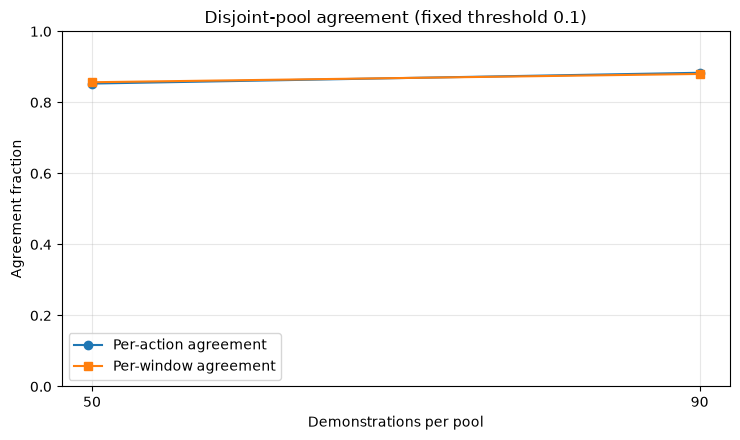

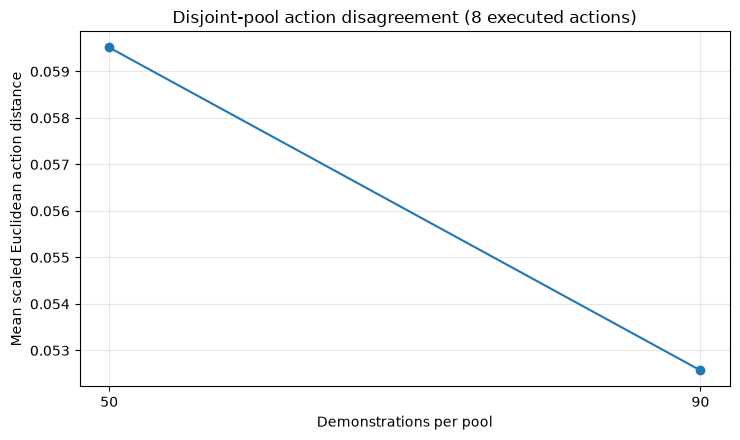

Plots saved to C:\Users\rrbhat\Downloads\dp_memorization\disjoint_split


In [8]:
s = summary.sort_values("n_demos")
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(s["n_demos"], s["action_agreement_ratio_executed8"], marker="o", label="Per-action agreement")
ax.plot(s["n_demos"], s["window_agreement_ratio_executed8"], marker="s", label="Per-window agreement")
ax.set(xlabel="Demonstrations per pool", ylabel="Agreement fraction",
       title=f"Disjoint-pool agreement (fixed threshold {AGREEMENT_THRESHOLD:g})", ylim=(0,1))
ax.set_xticks(PAIRS)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "agreement_vs_dataset_size.png", dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(7.5,4.5))
ax.plot(s["n_demos"], s["mean_scaled_action_distance_executed8"], marker="o")
ax.set(xlabel="Demonstrations per pool", ylabel="Mean scaled Euclidean action distance",
       title="Disjoint-pool action disagreement (8 executed actions)")
ax.set_xticks(PAIRS)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUT_DIR / "action_distance_vs_dataset_size.png", dpi=180)
plt.show()
print("Plots saved to", OUT_DIR)

## Step 8 — Optional: relate agreement to the previously saved task scores

The individual rollout scores are **not** action-agreement measurements. They show whether each policy succeeds in Push-T. This table makes it easier to discuss whether greater agreement accompanies higher task performance.

In [9]:
score_rows = []
for n in PAIRS:
    row = {"n_demos": n}
    for pool in ("A", "B"):
        path = PROJECT_DIR / "results" / f"N{n:03d}_pool{pool}_seed{MODEL_SEED}.json"
        if path.is_file():
            with open(path, encoding="utf-8") as f:
                r = json.load(f)
            row[f"pool_{pool}_mean_score"] = r["mean_score"]
            row[f"pool_{pool}_success_rate"] = r["success_rate"]
        else:
            print("Missing optional evaluation JSON:", path)
    score_rows.append(row)
performance = pd.DataFrame(score_rows)
combined = summary.merge(performance, on="n_demos", how="left")
combined.to_csv(OUT_DIR / "disjoint_with_task_scores.csv", index=False)
display(combined)

,n_demos,n_observation_windows,n_heldout_episodes,inference_seed,agreement_threshold,mean_scaled_action_distance_executed8,median_scaled_action_distance_executed8,action_agreement_ratio_executed8,window_agreement_ratio_executed8,mean_scaled_action_distance_full16,pool_A_mean_score,pool_A_success_rate,pool_B_mean_score,pool_B_success_rate
0,50,300,20,2026,0.1,0.059515,0.038000,0.852917,0.856667,0.069363,0.726795,0.56,0.708492,0.30
1,90,300,20,2026,0.1,0.052571,0.035331,0.883333,0.880000,0.062080,0.894433,0.64,0.877553,0.52


## Interpretation and handoff

**What you can report:** For N=50 and N=90, measured action agreement between models trained on disjoint demonstrations, with the same held-out observation inputs, sampling seed, fixed scaling and threshold. Complement that with each model's separately evaluated Push-T mean scores and success rates.

**What you cannot conclude from this alone:** Agreement does not independently establish generalization, because both policies may agree on poor actions. One inference seed is a controlled single draw, not a measure of diffusion-sampling uncertainty. Your results may be sensitive to the scaling, threshold and particular 20 held-out demonstrations. Also, note the original training notebook fit its normalizer using the full dataset, including held-out demonstrations; this is a preprocessing leakage caveat for claims about fully unseen inputs, although every model uses the same normalizer. Address it explicitly in your report rather than silently changing the trained models.

**Files to share:** `disjoint_summary.csv`, `disjoint_per_observation.csv`, `N050_...paired_predictions.npz`, `N090_...paired_predictions.npz`, both PNG plots and the associated analysis notebook. Preserve the original checkpoints separately; they are not included in this notebook download.

**For more rigorous confidence intervals:** bootstrap at the **held-out demonstration level** (20 groups), not over correlated adjacent timesteps. To evaluate sampler variability, rerun inference for multiple registered `INFERENCE_SEED` values and summarize across repeats.